# Dự báo khách ngày: baseline và hồi quy với ba fold

So sánh B0–B4 và 5 họ ML, hai nhánh canonical/imputed, dự báo 7 horizon trực tiếp.

Bản viết lại từ `history_demand_imputed_3fold.ipynb`, bản cũ được giữ nguyên.
Chọn kernel `.venv`, chạy từ trên xuống (Restart Kernel → Run All).
Nguồn mặc định là snapshot cố định đã lưu, không cần PostgreSQL hoặc `docs/ml` cũ.
Quality PASS là evidence của snapshot, không phải kiểm tra DB mới.
Target là khách của booking cuối cùng không hủy theo ngày đến, không phải occupancy/check-in thực.
Holdout 06–08/2017 đã được xem ở thí nghiệm trước, kết quả là hồi cứu, mang tính khám phá.

## 1. Thiết lập

Chỉ dùng các thư viện đã có trong `ml/requirements.txt`. Mỗi lần chạy tạo
thư mục artifact riêng, không sửa dữ liệu nguồn hoặc kết quả cũ.

In [1]:
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pipeline/config/dw_operations.json').is_file())
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

In [2]:
SOURCE_DIR = ROOT / 'artifacts/forecasting/history_demand_causal_methods/20261109T110426_146bf398'
NOTEBOOK_PATH = ROOT / 'notebooks/experiments/history_demand_imputed_3fold_report.ipynb'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid4().hex[:8]
OUT = ROOT / 'artifacts/forecasting/history_demand_imputed_3fold_report' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
DAY = pd.Timedelta(days=1)
TRAIN_START, TEST_END = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
SEED = 42
print('Artifacts:', OUT.relative_to(ROOT))

Artifacts: artifacts\forecasting\history_demand_imputed_3fold_report\20261110T051148_553f2ff2


In [3]:
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(name, value):
    with (OUT / name).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, ensure_ascii=False, indent=2, default=str, allow_nan=False)
def save_csv(name, frame):
    frame.to_csv(OUT / name, index=False, float_format='%.12g')
save_json('environment.json', {'python': platform.python_version(), **{
    name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'scikit-learn')}})

## 2. Load data và kiểm tra nguồn

Kiểm tra checksum trước khi đọc. Daily và booking phải thuộc cùng published snapshot,
khóa booking là checksum nguồn + row ordinal. Không gộp dòng vì giống thuộc tính.

In [4]:
inventory = json.loads((SOURCE_DIR / 'input_manifest.json').read_text(encoding='utf-8'))
for name in ('daily_input.csv', 'booking_input.csv', 'provenance.json', 'quality.json'):
    assert sha(SOURCE_DIR / name) == inventory[name], f'Input changed: {name}'
provenance = json.loads((SOURCE_DIR / 'provenance.json').read_text(encoding='utf-8'))
quality = json.loads((SOURCE_DIR / 'quality.json').read_text(encoding='utf-8'))
assert all(q['passed'] and not q['errors'] for q in quality.values())
assert all(q['data_version'] == provenance['data_version'] for q in quality.values())
daily = pd.read_csv(SOURCE_DIR / 'daily_input.csv', parse_dates=['full_date'])
bookings = pd.read_csv(SOURCE_DIR / 'booking_input.csv', parse_dates=['full_date'])
print('Data version:', provenance['data_version'])
pd.DataFrame({'dataset': ['daily', 'booking'], 'rows': [len(daily), len(bookings)]})

Data version: 323b1759-994c-4c66-8ca3-8d73e5a11acb


,dataset,rows
0,daily,793
1,booking,79250


In [5]:
daily_ints = ['date_key', 'observed_total_guests', 'target_guests', 'non_canceled_bookings',
              'guest_valid_booking_count', 'missing_guest_bookings_count',
              'guest_ineligible_booking_count', 'rejected_booking_count', 'excluded_booking_count']
for frame, names in ((daily, daily_ints), (bookings, ['source_row_id', 'is_canceled', 'total_guests'])):
    for name in names:
        values = pd.to_numeric(frame[name], errors='raise')
        frame[name] = values.astype('Int64')
assert pd.DatetimeIndex(daily.full_date).equals(pd.date_range(TRAIN_START, TEST_END))
assert set(daily.data_version) == {provenance['data_version']}
assert daily.guest_data_status.eq('COMPLETE').equals(daily.target_guests.notna())
assert set(bookings.source_file_sha256) == {provenance['source_checksums']['booking']}

In [6]:
valid = bookings[(bookings.is_canceled == 0) & bookings.guest_eligible].copy()
observed = valid.groupby('full_date').total_guests.agg(['sum', 'count'])
observed = observed.reindex(daily.full_date, fill_value=0)
np.testing.assert_array_equal(observed['sum'], daily.observed_total_guests)
np.testing.assert_array_equal(observed['count'], daily.guest_valid_booking_count)
source_hashes = {name: sha(SOURCE_DIR / name) for name in inventory}
old_paths = [p for p in (ROOT / 'notebooks').rglob('*.ipynb') if not p.stem.endswith('_report')]
old_hashes = {str(p.relative_to(ROOT)): sha(p) for p in old_paths}
save_json('source.json', {'snapshot': str(SOURCE_DIR.relative_to(ROOT)), 'provenance': provenance,
                          'input_checksums': source_hashes, 'point_in_time_verified': False})

### Bổ sung loại phòng đặt

Snapshot booking chưa có loại phòng. Đọc `reserved_room_type` từ đúng raw đã ghim
checksum, ghép bằng row ordinal, chỉ giữ booking đã có trong snapshot.
Đây là thuộc tính phục vụ bù nhãn, không phải feature tương lai đưa vào model.

In [7]:
source_set = json.loads((ROOT / 'docs/data_dictionary/operations_source_set.json').read_text(encoding='utf-8'))
room_source = source_set['sources']['booking']
room_path = ROOT / room_source['file']
assert sha(room_path) == room_source['sha256'] == provenance['source_checksums']['booking']
room_rows = pd.read_csv(room_path, usecols=['reserved_room_type'], keep_default_na=False)
room_rows['source_row_id'] = np.arange(2, len(room_rows) + 2)
bookings = bookings.merge(room_rows, on='source_row_id', how='left', validate='one_to_one', indicator=True)
assert bookings._merge.eq('both').all(), 'Room source does not cover the snapshot'
bookings = bookings.drop(columns='_merge')
bookings['reserved_room_type'] = bookings.reserved_room_type.astype('string').str.strip().replace('', pd.NA)
valid = bookings[bookings.is_canceled.eq(0) & bookings.guest_eligible].copy()
save_json('room_source.json', {'file': room_source['file'], 'sha256': sha(room_path),
                             'join_key': 'source checksum + source_row_id', 'rows': len(bookings)})
bookings[['source_row_id', 'full_date', 'reserved_room_type', 'total_guests', 'guest_eligible']].head()

,source_row_id,full_date,reserved_room_type,total_guests,guest_eligible
0,40062,2015-07-01,A,1,True
1,40063,2015-07-01,A,2,True
2,40064,2015-07-01,A,1,True
3,40065,2015-07-01,A,2,True
4,74968,2015-07-01,A,2,True


## 3. Chia dữ liệu và fold

Dùng `sklearn.model_selection.TimeSeriesSplit(n_splits=3)` trên trục ngày
development 07/2015–05/2017. Ba validation fold có cùng số ngày, train mở rộng dần.
Giữ đủ ngày khi chia, không drop ngày thiếu hoặc fit imputer trên toàn bộ dữ liệu.
Mean bù, median và scaler vẫn chỉ học từ train của từng fold.
Holdout 06–08/2017 tách riêng. Dự báo cuối ngày t cho t+1…t+7, origin từ
eval_start−1 đến eval_end−7 để mọi origin có đủ 7 horizon.
Delay nhãn = **0 ngày** là giả định khả dụng, cutoff nhãn lùi trong train tương ứng.
Chọn model bằng trung bình đều MAE ba fold, trong 1% ưu tiên model đơn giản.

In [8]:
from sklearn.model_selection import TimeSeriesSplit
HORIZONS = tuple(range(1, 8))
DELAY = 0
DEV_END = pd.Timestamp('2017-05-31')
development_dates = pd.DatetimeIndex(daily.loc[daily.full_date.le(DEV_END), 'full_date'])
splitter = TimeSeriesSplit(n_splits=3)
FOLDS = []
for number, (train_index, val_index) in enumerate(splitter.split(development_dates), 1):
    FOLDS.append({'fold': f'F{number}',
        'train_end': str(development_dates[train_index[-1]].date()),
        'eval_start': str(development_dates[val_index[0]].date()),
        'eval_end': str(development_dates[val_index[-1]].date())})

In [9]:
HOLDOUT = {'fold': 'Holdout', 'train_end': '2017-05-31', 'eval_start': '2017-06-01', 'eval_end': '2017-08-31'}
fold_table = pd.DataFrame(FOLDS + [HOLDOUT])
fold_table['train_days'] = (pd.to_datetime(fold_table.train_end) - TRAIN_START).dt.days + 1
fold_table['eval_days'] = (pd.to_datetime(fold_table.eval_end) - pd.to_datetime(fold_table.eval_start)).dt.days + 1
fold_table['available_train_end'] = pd.to_datetime(fold_table.train_end) - DELAY * DAY
save_csv('fold_manifest.csv', fold_table)
fold_table

,fold,train_end,eval_start,eval_end,train_days,eval_days,available_train_end
0,F1,2015-12-23,2015-12-24,2016-06-15,176,175,2015-12-23
1,F2,2016-06-15,2016-06-16,2016-12-07,351,175,2016-06-15
2,F3,2016-12-07,2016-12-08,2017-05-31,526,175,2016-12-07
3,Holdout,2017-05-31,2017-06-01,2017-08-31,701,92,2017-05-31


In [10]:
def schedule(start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    origins = pd.date_range(start - DAY, end - 7 * DAY)
    return pd.DataFrame([(t, h, t + h * DAY) for t in origins for h in HORIZONS],
                        columns=['origin', 'horizon', 'target_date'])

## 4. Tiền xử lý và nhãn theo từng fold

Chia tập trước khi fit. PARTIAL chỉ được bù khi phần thiếu thuộc ZERO_GUESTS đã
được chấp nhận và coverage/reconciliation đủ điều kiện. Công thức: observed subtotal
+ tổng mean theo loại phòng của các booking thiếu. Giữ COMPLETE, kể cả zero.
Median/scaler chỉ fit train từng horizon. Mean theo phòng của train bù cả history train,
đây là preprocessing trong train, không phải replay khả dụng từng training row.

In [11]:
MODELS = ('B0_mean', 'B1_seasonal', 'B2_ma7', 'B3_ma14', 'B4_weekday')
ML_MODELS = ('M0_linear', 'M1_ridge', 'M2_random_forest', 'M3_extra_trees', 'M4_hist_gb')
VARIANTS = ('canonical_history', 'imputed_history')
POLICY = {'warmup_days': 28, 'correction_lambda': 10, 'seed': SEED}

### Mean theo loại phòng trong train

Tính số khách/booking hợp lệ, không hủy, theo `reserved_room_type`.
Nhóm có ít nhất **30 booking** dùng mean riêng, nhóm ít mẫu/không biết/chưa gặp
dùng mean chung train. Ngưỡng 30 cố định, không chọn bằng điểm test.
Bù từng booking ZERO_GUESTS đủ điều kiện rồi cộng với subtotal quan sát của ngày.
Giữ nguyên ngày COMPLETE và zero hợp lệ. Nhãn sau bù vẫn là ước tính.

In [12]:
MIN_ROOM_BOOKINGS = 30
IMPUTATION_POLICY = {'method': 'room_type_mean', 'group_column': 'reserved_room_type',
                     'min_room_bookings': MIN_ROOM_BOOKINGS, 'fallback': 'train_global_mean'}
def fit_room_imputer(cutoff):
    train = valid[valid.full_date.between(TRAIN_START, pd.Timestamp(cutoff))]
    mu = float(train.total_guests.mean())
    rooms = train.groupby('reserved_room_type').total_guests.agg(['count', 'sum', 'mean'])
    rooms['use_room_mean'] = rooms['count'].ge(MIN_ROOM_BOOKINGS)
    rooms['fill_mean'] = rooms['mean'].where(rooms.use_room_mean, mu)
    return {**IMPUTATION_POLICY, 'mu_train': mu, 'fit_start': str(TRAIN_START.date()),
            'fit_end': str(pd.Timestamp(cutoff).date()), 'fit_label_cutoff': str(pd.Timestamp(cutoff).date()),
            'known_guest_sum': int(train.total_guests.sum()), 'known_booking_count': len(train),
            'rooms': rooms.to_dict(orient='index')}

In [13]:
def room_mean_table(imputer):
    return pd.DataFrame.from_dict(imputer['rooms'], orient='index').rename_axis('reserved_room_type').reset_index()
def room_estimates(imputer, end):
    mask = bookings.is_canceled.eq(0) & ~bookings.guest_eligible & bookings.full_date.le(pd.Timestamp(end))
    missing = bookings.loc[mask].copy()
    means = {room: stats['fill_mean'] for room, stats in imputer['rooms'].items()}
    used = {room: stats['use_room_mean'] for room, stats in imputer['rooms'].items()}
    missing['estimated_guests'] = missing.reserved_room_type.map(means).astype(float).fillna(imputer['mu_train'])
    missing['imputation_source'] = np.where(missing.reserved_room_type.map(used).eq(True), 'ROOM_MEAN', 'GLOBAL_MEAN')
    return missing
def save_room_imputation(prefix, imputer, end):
    save_json(prefix + '_imputer.json', imputer)
    save_csv(prefix + '_room_means.csv', room_mean_table(imputer))
    save_csv(prefix + '_imputed_bookings.csv', room_estimates(imputer, end))

In [14]:
def eligible_imputation(frame):
    return (frame.guest_data_status.eq('PARTIAL') & frame.booking_data_status.eq('COMPLETE')
            & frame.rejected_booking_count.eq(frame.excluded_booking_count)
            & frame.missing_guest_bookings_count.gt(0)
            & frame.guest_ineligible_booking_count.eq(frame.missing_guest_bookings_count)
            & frame.non_canceled_bookings.eq(frame.guest_valid_booking_count + frame.missing_guest_bookings_count))

In [15]:
def room_labels(cutoff, end):
    frame = daily[daily.full_date.le(pd.Timestamp(end))].copy()
    imputer = fit_room_imputer(cutoff)
    additions = room_estimates(imputer, end).groupby('full_date').estimated_guests.sum()
    frame['target_true'] = frame.target_guests.astype(float)
    frame['estimated_missing_guests'] = frame.full_date.map(additions).fillna(0.)
    mask = eligible_imputation(frame)
    frame.loc[~mask, 'estimated_missing_guests'] = 0.
    frame['target_estimated'] = frame.target_true.copy()
    frame.loc[mask, 'target_estimated'] = (frame.loc[mask, 'observed_total_guests'].astype(float)
                                         + frame.loc[mask, 'estimated_missing_guests'])
    frame['target_is_imputed'] = mask.to_numpy(dtype=bool)
    frame['partition'] = np.where(frame.full_date.le(pd.Timestamp(cutoff)), 'train', 'evaluation')
    return frame, imputer

In [16]:
preview_imputer = fit_room_imputer(pd.Timestamp(FOLDS[0]['train_end']))
print('Mean chung train:', round(preview_imputer['mu_train'], 6), ', tối thiểu', MIN_ROOM_BOOKINGS, 'booking/loại phòng')
room_mean_table(preview_imputer).round(4)

Mean chung train: 1.779978 , tối thiểu 30 booking/loại phòng


,reserved_room_type,count,sum,mean,use_room_mean,fill_mean
0,A,6375,10930,1.7145,True,1.7145
1,B,143,300,2.0979,True,2.0979
2,C,2,5,2.5000,False,1.7800
3,D,562,1108,1.9715,True,1.9715
4,E,42,75,1.7857,True,1.7857
5,F,131,480,3.6641,True,3.6641
6,G,17,46,2.7059,False,1.7800


In [17]:
def fold_labels(fold):
    return room_labels(fold['train_end'], fold['eval_end'])

In [18]:
def history_stats(series):
    result = pd.DataFrame(index=series.index)
    for size in (7, 14, 28):
        result[f'n{size}'] = series.rolling(size, min_periods=1).count()
        result[f'm{size}'] = series.rolling(size, min_periods=1).mean()
    return result
def reference(series, cutoff):
    known = series.loc[:cutoff].dropna()
    by_weekday = known.groupby(known.index.day_of_week).mean()
    return {'global_mean': float(known.mean()),
            'weekday_mean': [float(by_weekday.get(w, known.mean())) for w in range(7)]}

In [19]:
def ml_features(series, pairs):
    """Build features using history through origin and known target-date calendar only."""
    origin = pd.DatetimeIndex(pairs.origin)
    target = pd.DatetimeIndex(pairs.target_date)
    values = {}
    for lag in (0, 1, 2, 6, 7, 13, 14, 20, 27):
        values[f'y_origin_minus_{lag}'] = series.reindex(origin - lag * DAY).to_numpy()
    for size in (7, 14, 28):
        window = series.rolling(size, min_periods=1)
        for name, stat in (('mean', window.mean()), ('std', window.std(ddof=0)), ('count', window.count())):
            values[f'{name}_{size}'] = stat.reindex(origin).to_numpy()
    for lag in (7, 14, 28):
        history_date = target - lag * DAY
        values[f'target_lag_{lag}'] = series.reindex(history_date).to_numpy()
    for weekday in range(1, 7):
        values[f'target_weekday_{weekday}'] = (target.day_of_week == weekday).astype(float)
    phase = 2 * np.pi * (target.day_of_year - 1) / 365.25
    values['target_year_sin'] = np.sin(phase)
    values['target_year_cos'] = np.cos(phase)
    values['target_trend_days'] = (target - TRAIN_START).days.astype(float)
    return pd.DataFrame(values, index=pairs.index, dtype=float)

## 5. Kiến trúc và cấu hình mô hình

Baseline: B0 mean train, B1 cùng thứ lag 7→14→21→28, B2 MA7 (≥4 nhãn)
→MA14 (≥7)→MA28 (≥10), B3 MA14→MA28, cuối cùng fallback weekday mean train.
B4 thêm residual horizon×weekday, shrink n/(n+10). Prediction chặn dưới 0.

ML: LinearRegression, Ridge alpha=10, RF 150 cây/depth 8/leaf 5,
ExtraTrees 150/depth 10/leaf 5, HistGB 200 iterations/lr .05/15 leaves/L2=1.
Mỗi họ fit 7 model riêng, không grid search, early stopping HistGB tắt.
Input gồm lag origin 0/1/2/6/7/13/14/20/27, rolling 7/14/28,
target-relative lag 7/14/28, weekday, sin/cos năm và trend ngày.

In [20]:
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
ML_CONFIG = {
    'M0_linear': {}, 'M1_ridge': {'alpha': 10.},
    'M2_random_forest': {'n_estimators': 150, 'max_depth': 8, 'min_samples_leaf': 5,
                         'max_features': 1., 'random_state': SEED, 'n_jobs': 1},
    'M3_extra_trees': {'n_estimators': 150, 'max_depth': 10, 'min_samples_leaf': 5,
                       'max_features': 1., 'random_state': SEED, 'n_jobs': 1},
    'M4_hist_gb': {'max_iter': 200, 'learning_rate': .05, 'max_leaf_nodes': 15,
                   'min_samples_leaf': 15, 'l2_regularization': 1.,
                   'early_stopping': False, 'random_state': SEED},
}
pd.DataFrame(ML_CONFIG).T

,alpha,n_estimators,max_depth,min_samples_leaf,max_features,random_state,n_jobs,max_iter,learning_rate,max_leaf_nodes,l2_regularization,early_stopping
M0_linear,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M1_ridge,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M2_random_forest,NaN,150.0,8.0,5.0,1.0,42.0,1.0,NaN,NaN,NaN,NaN,NaN
M3_extra_trees,NaN,150.0,10.0,5.0,1.0,42.0,1.0,NaN,NaN,NaN,NaN,NaN
M4_hist_gb,NaN,NaN,NaN,15,NaN,42,NaN,200,0.05,15,1.0,False


In [21]:
def make_ml_model(name):
    estimators = {'M0_linear': LinearRegression, 'M1_ridge': Ridge,
                  'M2_random_forest': RandomForestRegressor, 'M3_extra_trees': ExtraTreesRegressor,
                  'M4_hist_gb': HistGradientBoostingRegressor}
    steps = [SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)]
    if name in ('M0_linear', 'M1_ridge'):
        steps.append(StandardScaler())
    return make_pipeline(*steps, estimators[name](**ML_CONFIG[name]))

### In feature đầu vào

In đủ tên, kiểu dữ liệu và mẫu giá trị của feature gốc cho hai nhánh.
Minh họa trên train F1, target được giữ riêng, không đưa vào X.
In thêm tên cột sau median/missing indicator/StandardScaler cho horizon 1.
Danh sách cột gốc giống nhau giữa các horizon, indicator có thể khác tùy missing trong train.

In [22]:
preview_labels, _ = fold_labels(FOLDS[0])
preview_pairs = schedule(TRAIN_START + 29 * DAY, pd.Timestamp(FOLDS[0]['train_end']))
preview_series = preview_labels.set_index('full_date')[['target_true', 'target_estimated']]
feature_inputs = {variant: ml_features(preview_series[column], preview_pairs)
                  for variant, column in zip(VARIANTS, preview_series.columns)}
feature_catalog = pd.DataFrame({'feature': feature_inputs['canonical_history'].columns,
    'dtype': feature_inputs['canonical_history'].dtypes.astype(str).to_numpy()})
print('Số feature gốc:', len(feature_catalog))
feature_catalog

Số feature gốc: 30


,feature,dtype
0,y_origin_minus_0,float64
1,y_origin_minus_1,float64
2,y_origin_minus_2,float64
3,y_origin_minus_6,float64
4,y_origin_minus_7,float64
5,y_origin_minus_13,float64
6,y_origin_minus_14,float64
7,y_origin_minus_20,float64
8,y_origin_minus_27,float64
9,mean_7,float64


In [23]:
save_csv('feature_catalog.csv', feature_catalog)

In [24]:
preview_pairs.head(3)

,origin,horizon,target_date
0,2015-07-29,1,2015-07-30
1,2015-07-29,2,2015-07-31
2,2015-07-29,3,2015-08-01


In [25]:
for variant, x in feature_inputs.items():
    print(f'{variant}: mẫu feature gốc, mỗi cột là một cặp origin/horizon')
    display(x.head(3).T.rename_axis('feature'))

canonical_history: mẫu feature gốc, mỗi cột là một cặp origin/horizon
imputed_history: mẫu feature gốc, mỗi cột là một cặp origin/horizon


,0,1,2
feature,,,
y_origin_minus_0,19.000000,19.000000,19.000000
y_origin_minus_1,17.000000,17.000000,17.000000
y_origin_minus_2,50.000000,50.000000,50.000000
y_origin_minus_6,NaN,NaN,NaN
y_origin_minus_7,47.000000,47.000000,47.000000
y_origin_minus_13,2.000000,2.000000,2.000000
y_origin_minus_14,50.000000,50.000000,50.000000
y_origin_minus_20,2.000000,2.000000,2.000000
y_origin_minus_27,1.000000,1.000000,1.000000


,0,1,2
feature,,,
y_origin_minus_0,19.000000,19.000000,19.000000
y_origin_minus_1,17.000000,17.000000,17.000000
y_origin_minus_2,50.000000,50.000000,50.000000
y_origin_minus_6,74.714510,74.714510,74.714510
y_origin_minus_7,47.000000,47.000000,47.000000
y_origin_minus_13,2.000000,2.000000,2.000000
y_origin_minus_14,50.000000,50.000000,50.000000
y_origin_minus_20,2.000000,2.000000,2.000000
y_origin_minus_27,1.000000,1.000000,1.000000


In [26]:
for variant, column in zip(VARIANTS, preview_series.columns):
    x = feature_inputs[variant]
    y = preview_series[column].reindex(pd.DatetimeIndex(preview_pairs.target_date)).to_numpy()
    mask = preview_pairs.horizon.eq(1).to_numpy() & np.isfinite(y)
    preprocessing = make_ml_model('M0_linear')[:-1]
    values = preprocessing.fit_transform(x.loc[mask])
    names = preprocessing.get_feature_names_out()
    print(f'{variant}, F1/h=1: {len(names)} feature sau tiền xử lý')
    display(pd.DataFrame({'feature_after_preprocessing': names}))
    display(pd.DataFrame(values[:3], columns=names).T.rename_axis('feature'))

canonical_history, F1/h=1: 42 feature sau tiền xử lý
imputed_history, F1/h=1: 30 feature sau tiền xử lý


,feature_after_preprocessing
0,y_origin_minus_0
1,y_origin_minus_1
2,y_origin_minus_2
3,y_origin_minus_6
4,y_origin_minus_7
5,y_origin_minus_13
6,y_origin_minus_14
7,y_origin_minus_20
8,y_origin_minus_27
9,mean_7


,0,1,2
feature,,,
y_origin_minus_0,-1.148348,-1.373359,-1.279604
y_origin_minus_1,-1.167443,-1.130289,-1.353213
y_origin_minus_2,-0.573401,-1.189228,-1.151905
y_origin_minus_6,-0.157662,-1.367354,-0.157662
y_origin_minus_7,-0.687539,-0.201324,-1.379462
y_origin_minus_13,-1.541570,0.167772,0.010591
y_origin_minus_14,-0.602697,-1.555842,0.171734
y_origin_minus_20,-1.470275,-1.393327,-0.354531
y_origin_minus_27,-1.479074,-1.151161,-1.189739


,feature_after_preprocessing
0,y_origin_minus_0
1,y_origin_minus_1
2,y_origin_minus_2
3,y_origin_minus_6
4,y_origin_minus_7
5,y_origin_minus_13
6,y_origin_minus_14
7,y_origin_minus_20
8,y_origin_minus_27
9,mean_7


,0,1,2
feature,,,
y_origin_minus_0,-1.170111,-1.384563,-1.295208
y_origin_minus_1,-1.202604,-1.166917,-1.381040
y_origin_minus_2,-0.621439,-1.212998,-1.177146
y_origin_minus_6,-0.190943,-1.353560,0.509705
y_origin_minus_7,-0.684948,-0.187748,-1.348730
y_origin_minus_13,-1.490256,0.116671,-0.031092
y_origin_minus_14,-0.605154,-1.492365,0.115706
y_origin_minus_20,-1.450324,-1.377560,-0.395251
y_origin_minus_27,-1.399160,-1.096188,-1.131832


In [27]:
pd.DataFrame({'baseline': MODELS, 'đầu vào': [
    'Mean target train', 'Target cùng thứ lag 7/14/21/28, weekday mean train',
    'Rolling mean/count 7/14/28, weekday mean train',
    'Rolling mean/count 14/28, weekday mean train',
    'Đầu vào B3 + horizon + weekday + residual correction train',
]})

,baseline,đầu vào
0,B0_mean,Mean target train
1,B1_seasonal,"Target cùng thứ lag 7/14/21/28, weekday mean t..."
2,B2_ma7,"Rolling mean/count 7/14/28, weekday mean train"
3,B3_ma14,"Rolling mean/count 14/28, weekday mean train"
4,B4_weekday,Đầu vào B3 + horizon + weekday + residual corr...


In [28]:
def moving_average(series, stats, origin, model, weekday, ref):
    windows = [(7, 4), (14, 7), (28, 10)] if model == 'B2_ma7' else [(14, 7), (28, 10)]
    for size, minimum in windows:
        if stats.at[origin, f'n{size}'] >= minimum:
            return float(stats.at[origin, f'm{size}']), f'MA{size}'
    return ref['weekday_mean'][weekday], 'TRAIN_WEEKDAY_MEAN'
def baseline(model, series, stats, origin, horizon, ref, correction=None):
    target = origin + horizon * DAY
    weekday = target.day_of_week
    if model == 'B0_mean':
        return ref['global_mean'], 'TRAIN_MEAN'
    if model == 'B1_seasonal':
        for lag in (7, 14, 21, 28):
            value = series.get(target - lag * DAY, np.nan)
            if pd.notna(value):
                return float(value), f'LAG{lag}'
        return ref['weekday_mean'][weekday], 'TRAIN_WEEKDAY_MEAN'
    value, rule = moving_average(series, stats, origin, model, weekday, ref)
    if model == 'B4_weekday':
        value += correction[horizon - 1][weekday]
        rule += '+CORRECTION'
    return max(0., float(value)), rule

## 6. Train trên từng fold

Warm-up 28 ngày, mọi train target dừng trong cutoff. B4 calibration chỉ fit
trong train, ML fit median/scaler/model riêng theo horizon và nhánh.
Các tham số giữ nguyên trong kỳ đánh giá, feature history cập nhật cuốn chiếu.

In [29]:
def fit_baseline(series, stats, cutoff):
    cutoff = pd.Timestamp(cutoff)
    ref = reference(series, cutoff)
    rows = []
    for origin in pd.date_range(TRAIN_START + POLICY['warmup_days'] * DAY, cutoff - 7 * DAY):
        causal_ref = reference(series, origin)
        for h in HORIZONS:
            target = origin + h * DAY
            actual = series.at[target]
            if pd.isna(actual):
                continue
            base, _ = baseline('B3_ma14', series, stats, origin, h, causal_ref)
            rows.append({'origin': origin, 'horizon': h, 'target_date': target,
                         'weekday': target.day_of_week, 'residual': float(actual) - base})
    residuals = pd.DataFrame(rows)
    correction = np.zeros((7, 7))
    for h in HORIZONS:
        for w in range(7):
            r = residuals.loc[(residuals.horizon == h) & (residuals.weekday == w), 'residual']
            correction[h - 1, w] = float(r.sum() / (len(r) + POLICY['correction_lambda']))
    return {'reference': ref, 'correction': correction.tolist(), 'fit_end': str(cutoff.date())}, residuals

In [30]:
def fit_direct_models(series, pairs):
    x = ml_features(series, pairs)
    y = series.reindex(pd.DatetimeIndex(pairs.target_date)).to_numpy()
    fitted = {name: {} for name in ML_MODELS}
    with threadpool_limits(limits=1):
        for horizon in HORIZONS:
            mask = pairs.horizon.eq(horizon).to_numpy() & np.isfinite(y)
            for name in ML_MODELS:
                model = make_ml_model(name)
                model.fit(x.loc[mask], y[mask])
                fitted[name][horizon] = model
    return fitted, x

In [31]:
def train_fold(fold):
    cutoff = pd.Timestamp(fold['train_end'])
    labels, imputer = fold_labels(fold)
    indexed = labels.set_index('full_date')
    pairs = schedule(TRAIN_START + 29 * DAY, cutoff)
    assert pairs.target_date.le(cutoff).all()
    states = {}
    for variant, column in zip(VARIANTS, ('target_true', 'target_estimated')):
        series = indexed[column]
        stats = history_stats(series)
        params, _ = fit_baseline(series, stats, cutoff)
        fitted, x = fit_direct_models(series, pairs)
        states[variant] = {'series': series, 'stats': stats, 'params': params, 'models': fitted}
        save_csv(f"{fold['fold']}_{variant}_train.csv", pd.concat([pairs, x], axis=1))
    save_room_imputation(fold['fold'], imputer, fold['eval_end'])
    save_csv(f"{fold['fold']}_labels.csv", labels)
    print(f"{fold['fold']}: train đến {cutoff.date()}, bù theo phòng, mean fallback {imputer['mu_train']:.6f}")
    return {'fold': fold, 'labels': labels, 'states': states, 'imputer': imputer}

In [32]:
save_json('protocol.json', {'folds': FOLDS, 'holdout': HOLDOUT, 'label_delay': DELAY,
    'splitter': {'class': 'sklearn.model_selection.TimeSeriesSplit', 'n_splits': 3,
                 'test_size': splitter.test_size, 'gap': splitter.gap},
    'imputation': IMPUTATION_POLICY, 'ml_config': ML_CONFIG, 'selection': 'equal-fold ALL_ESTIMATED MAE, 1% simplicity',
    'strategy': 'direct 7 horizon models, refit development before holdout'})
validation_states = [train_fold(fold) for fold in FOLDS]

F1: train đến 2015-12-23, bù theo phòng, mean fallback 1.779978
F2: train đến 2016-06-15, bù theo phòng, mean fallback 1.846038
F3: train đến 2016-12-07, bù theo phòng, mean fallback 1.914423


## Đánh giá hồi quy và nguyên tắc chọn model

Báo MAE, RMSE, WAPE (tỷ lệ), signed bias và số mẫu, riêng ALL_ESTIMATED,
COMPLETE_ONLY, IMPUTED_ONLY. Hai nhánh dùng cùng benchmark của fold.
Điểm là trên cặp origin/horizon có tương quan, không phải các ngày độc lập.

In [33]:
def score_groups(predictions, by_horizon=False):
    rows = []
    keys = ['fold', 'variant', 'model'] + (['horizon'] if by_horizon else [])
    for group_key, frame in predictions.groupby(keys):
        populations = {'ALL_ESTIMATED': frame.target_estimated.notna(),
                       'COMPLETE_ONLY': frame.target_true.notna(),
                       'IMPUTED_ONLY': frame.target_is_imputed}
        for population, mask in populations.items():
            q = frame.loc[mask]
            actual = q.target_true if population == 'COMPLETE_ONLY' else q.target_estimated
            errors = q.y_pred - actual
            n = len(q)
            total = float(actual.sum())
            rows.append({**dict(zip(keys, group_key)), 'population': population,
                         'scheduled_n': len(frame), 'scorable_n': n,
                         'unique_dates': q.target_date.nunique(),
                         'coverage': float(q.y_pred.notna().mean()) if n else np.nan,
                         'MAE': float(errors.abs().mean()) if n else np.nan,
                         'RMSE': float(np.sqrt((errors ** 2).mean())) if n else np.nan,
                         'WAPE': float(errors.abs().sum() / total) if total > 0 else np.nan,
                         'signed_bias': float(errors.mean()) if n else np.nan})
    return pd.DataFrame(rows)

In [34]:
def attach_truth(raw, labels):
    columns = ['full_date', 'target_true', 'target_estimated', 'target_is_imputed']
    result = raw.merge(labels[columns], left_on='target_date', right_on='full_date',
                       how='left', validate='many_to_one')
    return result
def select_model(scores, order):
    best = scores.min()
    return next(name for name in order if scores.loc[name] <= best * 1.01 + 1e-12)

## 7. Validation và khóa lựa chọn

Dự báo từng origin bằng model đã fit, lưu prediction trước khi gắn target.
Chọn riêng từng nhánh từ trung bình đều ba fold, không chọn từ test.

In [35]:
def forecast_fold(state):
    pairs = schedule(state['fold']['eval_start'], state['fold']['eval_end'])
    rows = []
    for variant, data in state['states'].items():
        for pair in pairs.itertuples(index=False):
            for name in MODELS:
                value, _ = baseline(name, data['series'], data['stats'], pair.origin,
                                    pair.horizon, data['params']['reference'], data['params']['correction'])
                rows.append({**pair._asdict(), 'variant': variant, 'model': name, 'y_pred': value})
        x = ml_features(data['series'], pairs)
        with threadpool_limits(limits=1):
            for name in ML_MODELS:
                for h in HORIZONS:
                    mask = pairs.horizon.eq(h)
                    values = data['models'][name][h].predict(x.loc[mask])
                    for pair, value in zip(pairs.loc[mask].itertuples(index=False), values):
                        rows.append({**pair._asdict(), 'variant': variant, 'model': name, 'y_pred': max(0., value)})
    raw = pd.DataFrame(rows).assign(fold=state['fold']['fold'])
    return raw

In [36]:
validation_parts = []
for state in validation_states:
    raw = forecast_fold(state)
    save_csv(state['fold']['fold'] + '_validation_unscored.csv', raw)
    validation_parts.append(attach_truth(raw, state['labels']))
validation = pd.concat(validation_parts, ignore_index=True)
validation_metrics = score_groups(validation)
save_csv('validation_predictions.csv', validation)
save_csv('validation_metrics.csv', validation_metrics)
save_csv('validation_by_horizon.csv', score_groups(validation, by_horizon=True))

In [37]:
scores = validation_metrics[validation_metrics.population.eq('ALL_ESTIMATED')]
ranking = scores.pivot(index=['variant', 'model'], columns='fold', values='MAE')
ranking = ranking.reindex(columns=['F1', 'F2', 'F3'])
ranking['macro_fold_MAE'] = ranking.mean(axis=1)
SELECTED = {variant: select_model(ranking.loc[variant, 'macro_fold_MAE'], MODELS + ML_MODELS)
            for variant in VARIANTS}
ranking = ranking.reset_index()
ranking['selected'] = ranking.apply(lambda row: SELECTED[row.variant] == row.model, axis=1)
save_csv('validation_ranking.csv', ranking)
save_json('selection.json', SELECTED)
selection_hash = sha(OUT / 'selection.json')
ranking.sort_values(['variant', 'macro_fold_MAE']).round(4)

fold,variant,model,F1,F2,F3,macro_fold_MAE,selected
4,canonical_history,B4_weekday,33.0646,30.8931,28.2842,30.7473,True
3,canonical_history,B3_ma14,34.3486,31.3368,30.4653,32.0502,False
2,canonical_history,B2_ma7,34.7861,32.0297,30.7890,32.5349,False
8,canonical_history,M3_extra_trees,42.2261,32.8764,28.4010,34.5012,False
7,canonical_history,M2_random_forest,46.5876,31.6094,28.1018,35.4329,False
9,canonical_history,M4_hist_gb,48.0789,35.3300,29.1929,37.5339,False
1,canonical_history,B1_seasonal,40.6056,36.4976,36.3694,37.8242,False
0,canonical_history,B0_mean,48.9174,53.8224,36.9990,46.5796,False
6,canonical_history,M1_ridge,86.9803,34.3265,28.6008,49.9692,False
5,canonical_history,M0_linear,422.9336,36.3088,28.4366,162.5597,False


In [38]:
print('Model đã khóa:', SELECTED)

Model đã khóa: {'canonical_history': 'B4_weekday', 'imputed_history': 'B4_weekday'}


## 8. Test sau khi khóa model

Refit cùng cấu hình trên development đến 31/05/2017. Chấm tất cả model để
đối chiếu, nhưng model được chọn vẫn giữ theo validation. Test không dùng tuning.

In [39]:
holdout_state = train_fold(HOLDOUT)
raw = forecast_fold(holdout_state)
save_csv('holdout_unscored.csv', raw)
holdout = attach_truth(raw, holdout_state['labels'])
holdout_metrics = score_groups(holdout)
save_csv('holdout_predictions.csv', holdout)
save_csv('holdout_metrics.csv', holdout_metrics)
save_csv('holdout_by_horizon.csv', score_groups(holdout, by_horizon=True))
chosen = holdout_metrics[holdout_metrics.apply(lambda row: SELECTED[row.variant] == row.model, axis=1)]
chosen[['variant', 'model', 'population', 'scorable_n', 'MAE', 'RMSE', 'WAPE', 'signed_bias']].round(4)

Holdout: train đến 2017-05-31, bù theo phòng, mean fallback 1.916031


,variant,model,population,scorable_n,MAE,RMSE,WAPE,signed_bias
12,canonical_history,B4_weekday,ALL_ESTIMATED,602,24.5487,32.6349,0.1674,0.7486
13,canonical_history,B4_weekday,COMPLETE_ONLY,567,24.0143,31.5490,0.1653,2.1531
14,canonical_history,B4_weekday,IMPUTED_ONLY,35,33.2072,46.8413,0.1957,-22.0033
42,imputed_history,B4_weekday,ALL_ESTIMATED,602,24.8964,32.9152,0.1697,2.1493
43,imputed_history,B4_weekday,COMPLETE_ONLY,567,24.2622,31.7608,0.1670,3.4917
44,imputed_history,B4_weekday,IMPUTED_ONLY,35,35.1704,47.8845,0.2072,-19.5973


## 9. Kiểm tra tính khả dụng và phép bù

Thay nhãn tương lai phải không đổi feature/prediction trước origin. Che ngẫu nhiên
1–2 booking COMPLETE để kiểm tra phần bù, không coi sai số tái dựng này là MAE forecast
hoặc bằng chứng missing thật là ngẫu nhiên.

In [40]:
future_safe = True
for state in validation_states + [holdout_state]:
    origin = pd.Timestamp(state['fold']['eval_start']) - DAY
    pairs = pd.DataFrame([(origin, h, origin + h * DAY) for h in HORIZONS],
                         columns=['origin', 'horizon', 'target_date'])
    for data in state['states'].values():
        changed = data['series'].copy()
        changed.loc[changed.index > origin] = 99999.
        before, after = ml_features(data['series'], pairs), ml_features(changed, pairs)
        future_safe &= before.equals(after)
        with threadpool_limits(limits=1):
            for h in HORIZONS:
                for models in data['models'].values():
                    future_safe &= bool(np.allclose(models[h].predict(before.iloc[[h-1]]), models[h].predict(after.iloc[[h-1]])))

In [41]:
reconstruction = []
for state in validation_states + [holdout_state]:
    dates = state['labels'].query('target_true.notna()').full_date
    dates = dates[dates.between(state['fold']['eval_start'], state['fold']['eval_end'])]
    rng = np.random.default_rng(SEED)
    errors = {'global_mean': [], 'room_mean': []}
    means = {room: stats['fill_mean'] for room, stats in state['imputer']['rooms'].items()}
    for _, group in valid[valid.full_date.isin(dates)].groupby('full_date'):
        if len(group) < 2:
            continue
        n = int(rng.integers(1, 3))
        hidden = group.iloc[rng.choice(len(group), size=n, replace=False)]
        removed = float(hidden.total_guests.sum())
        mu = state['imputer']['mu_train']
        estimated = hidden.reserved_room_type.map(means).astype(float).fillna(mu).sum()
        errors['global_mean'].append(n * mu - removed)
        errors['room_mean'].append(float(estimated) - removed)
    for method, values in errors.items():
        reconstruction.append({'fold': state['fold']['fold'], 'method': method, 'days': len(values),
                               'reconstruction_MAE': np.abs(values).mean(), 'bias': np.mean(values)})
pd.DataFrame(reconstruction).round(4)

,fold,method,days,reconstruction_MAE,bias
0,F1,global_mean,162,0.6293,-0.1510
1,F1,room_mean,162,0.6098,-0.1253
2,F2,global_mean,148,0.6212,-0.1951
3,F2,room_mean,148,0.6217,-0.1572
4,F3,global_mean,155,0.6158,0.0133
5,F3,room_mean,155,0.6106,0.0004
6,Holdout,global_mean,87,0.6748,-0.2519
7,Holdout,room_mean,87,0.6181,-0.2410


In [42]:
save_csv('reconstruction.csv', pd.DataFrame(reconstruction))

## 10. Kết quả và nhận xét

Đọc kết quả theo thứ tự validation → model đã chọn → test. ALL_ESTIMATED có
nhãn ước tính, COMPLETE_ONLY chỉ phản ánh tập ngày đầy đủ. Khác biệt nhỏ giữa
model chưa đủ kết luận ưu thế thống kê khi chưa có đánh giá bất định phù hợp.

In [43]:
comparison = ranking.merge(holdout_metrics.query("population == 'ALL_ESTIMATED'")
    [['variant', 'model', 'MAE', 'RMSE', 'WAPE']].rename(columns={'MAE': 'holdout_MAE'}),
    on=['variant', 'model'], validate='one_to_one')
comparison.sort_values(['variant', 'macro_fold_MAE']).round(4)

,variant,model,F1,F2,F3,macro_fold_MAE,selected,holdout_MAE,RMSE,WAPE
4,canonical_history,B4_weekday,33.0646,30.8931,28.2842,30.7473,True,24.5487,32.6349,0.1674
3,canonical_history,B3_ma14,34.3486,31.3368,30.4653,32.0502,False,25.7624,32.5795,0.1756
2,canonical_history,B2_ma7,34.7861,32.0297,30.7890,32.5349,False,25.9626,32.7319,0.1770
8,canonical_history,M3_extra_trees,42.2261,32.8764,28.4010,34.5012,False,24.9873,32.1725,0.1704
7,canonical_history,M2_random_forest,46.5876,31.6094,28.1018,35.4329,False,25.4245,31.9755,0.1733
9,canonical_history,M4_hist_gb,48.0789,35.3300,29.1929,37.5339,False,27.0080,33.5528,0.1841
1,canonical_history,B1_seasonal,40.6056,36.4976,36.3694,37.8242,False,34.3771,42.5663,0.2344
0,canonical_history,B0_mean,48.9174,53.8224,36.9990,46.5796,False,42.3209,51.2923,0.2885
6,canonical_history,M1_ridge,86.9803,34.3265,28.6008,49.9692,False,27.3125,35.0493,0.1862
5,canonical_history,M0_linear,422.9336,36.3088,28.4366,162.5597,False,27.5697,35.3745,0.1880


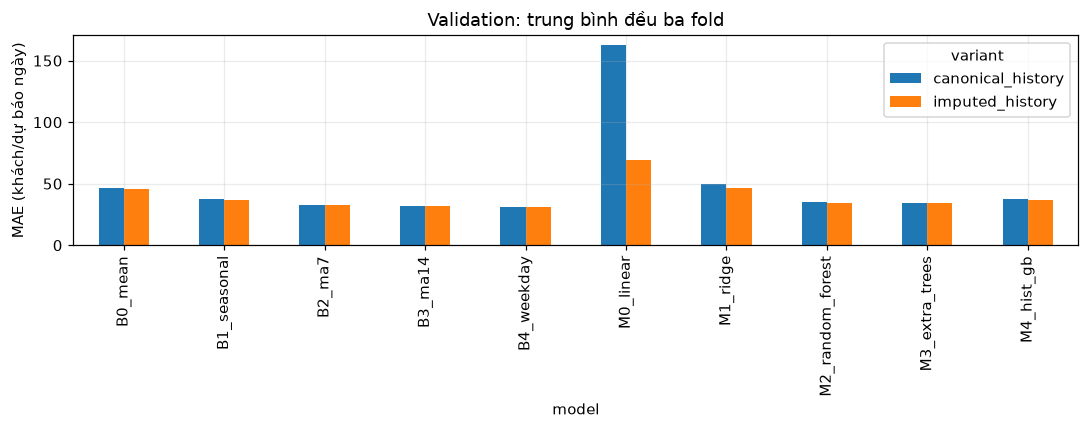

In [44]:
save_csv('comparison.csv', comparison)
fig, ax = plt.subplots(figsize=(10, 4))
ranking.pivot(index='model', columns='variant', values='macro_fold_MAE').plot.bar(ax=ax)
ax.set(ylabel='MAE (khách/dự báo ngày)', title='Validation: trung bình đều ba fold')
fig.tight_layout()
fig.savefig(OUT / 'validation.png')
plt.show()

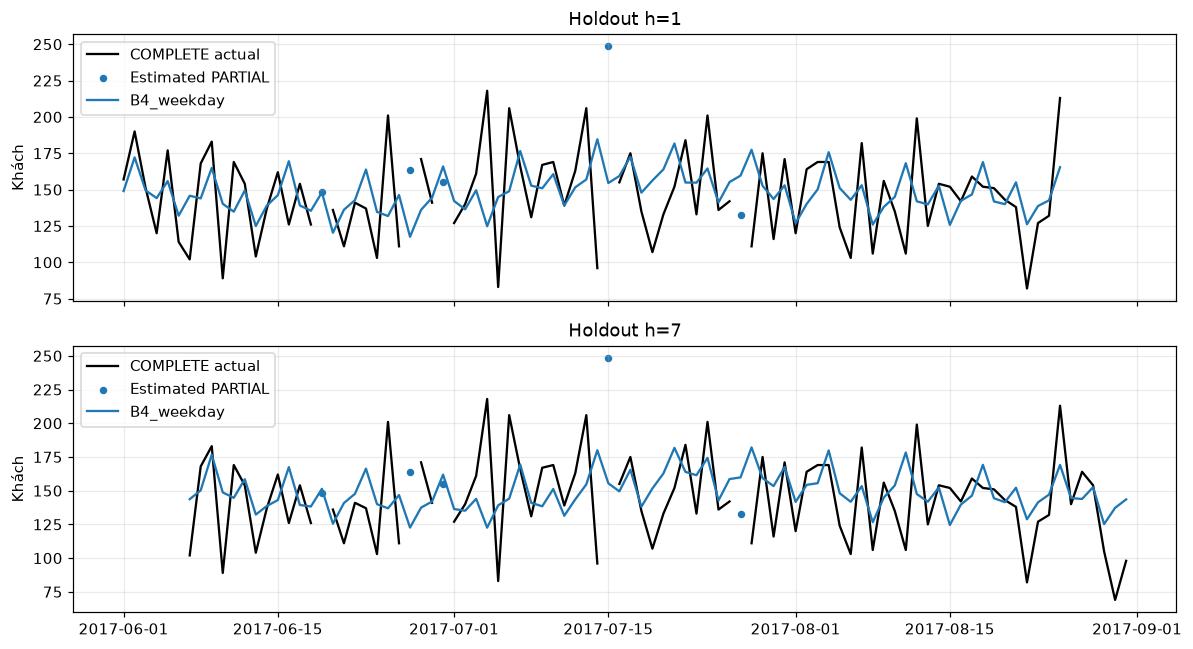

**canonical_history:** chọn **B4_weekday**, validation MAE **30.75**, test **24.55**.

**imputed_history:** chọn **B4_weekday**, validation MAE **30.73**, test **24.90**.

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, h in zip(axes, (1, 7)):
    data = holdout.query('variant == "imputed_history" and horizon == @h')
    selected = data[data.model.eq(SELECTED['imputed_history'])]
    ax.plot(selected.target_date, selected.target_true, color='black', label='COMPLETE actual')
    missing = selected[selected.target_is_imputed]
    ax.scatter(missing.target_date, missing.target_estimated, label='Estimated PARTIAL', s=15)
    ax.plot(selected.target_date, selected.y_pred, label=SELECTED['imputed_history'])
    ax.set(title=f'Holdout h={h}', ylabel='Khách')
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'holdout.png')
plt.show()
for variant in VARIANTS:
    row = comparison[comparison.variant.eq(variant) & comparison.selected].iloc[0]
    display(Markdown(f"**{variant}:** chọn **{row.model}**, validation MAE **{row.macro_fold_MAE:.2f}**, test **{row.holdout_MAE:.2f}**."))

## Lưu kết quả và kiểm tra khả năng chạy lại

Lưu bảng và manifest theo run riêng. Đối chiếu checksum nguồn và notebook cũ
sau thực nghiệm, các kết quả số ở trên được tính lại trong lần Run All này.

In [46]:
checks = {
    'inputs_unchanged': all(sha(SOURCE_DIR / name) == value for name, value in source_hashes.items()),
    'old_notebooks_unchanged': all(sha(ROOT / name) == value for name, value in old_hashes.items()),
    'selection_unchanged': sha(OUT / 'selection.json') == selection_hash,
    'future_feature_check': bool(future_safe),
    'room_source_unchanged': sha(room_path) == room_source['sha256'],
}
assert all(checks.values()), checks
save_json('verification.json', {'checks': checks, 'passed': True, 'fresh_execution': True,
                                'source_point_in_time_verified': False})
notebook = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
code_hash = hashlib.sha256(json.dumps([c['source'] for c in notebook['cells']
                          if c['cell_type'] == 'code'], ensure_ascii=False).encode()).hexdigest()
save_json('artifact_manifest.json', {'files': {p.name: sha(p) for p in OUT.iterdir() if p.is_file()},
                                      'notebook_code_sha256': code_hash})
pd.Series(checks, name='passed')

inputs_unchanged           True
old_notebooks_unchanged    True
selection_unchanged        True
future_feature_check       True
room_source_unchanged      True
Name: passed, dtype: bool

In [47]:
print('Hoàn tất:', OUT.relative_to(ROOT))

Hoàn tất: artifacts\forecasting\history_demand_imputed_3fold_report\20261110T051148_553f2ff2
